# Milestone 2: Cleaning, Optimized Storage and A/B Benchmark
## Data Engineering Lifecycle - BTS Airline Flight Delays Dataset

Each record is a monthly aggregate for one `(carrier, airport, year, month)` combination. The taxi-style tasks are mapped onto this domain:

| Task | NYC Taxi example | BTS equivalent used here |
|---|---|---|
| Business anomalies | negative tips | negative delay minutes / cause counts, missing measurements, broken sum invariants |
| Telemetry anomalies | trip shorter than 1 minute | zero operated flights, average delay per delayed flight outside the physically valid `[15 min, 24 h]` range |
| `trip_duration_minutes` | trip length | `avg_delay_minutes_per_delayed_flight` |
| `pickup_hour` | hour of pickup | `period_start`, `quarter`, `season`, `is_peak_travel_month` |
| `partition_cols=['VendorID']` | taxi vendor | `partition_cols=['carrier']` (airline) |
| Benchmark `WHERE VendorID = 1` | avg distance and tip per hour | avg delay per delayed flight and delay rate per month, `WHERE carrier = 'DL'` |

### 1. Environment preparation

In [1]:
import os
import statistics
import sys
import time
from pathlib import Path

ROOT_DIR = Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import duckdb
import matplotlib.pyplot as plt
import polars as pl
import pyarrow.parquet as pq
import seaborn as sns

from src.cleaning import (
    BUSINESS_RULES,
    TELEMETRY_RULES,
    add_features,
    anomaly_report,
    clean_business_anomalies,
    clean_telemetry_anomalies,
    describe_partitions,
    load_raw,
    write_partitioned_parquet,
    write_sorted_parquet,
)
from src.benchmark import (
    COLD_CACHE_SUPPORTED,
    LAYOUT_FLAT,
    LAYOUT_PARTITIONED,
    LAYOUT_SORTED,
    all_carriers_kpis,
    evict_page_cache,
    io_report,
    monthly_kpis,
    multi_carrier_kpis,
    run_ab_benchmark,
    run_scale_experiment,
    run_storage_experiment,
    size_mb,
    storage_info,
    summarize,
    top_airports,
    yearly_volume,
)
from src.config import (
    BENCHMARK_DIR,
    BTS_CSV_PATH,
    CLEANING_BENCHMARK_TXT_PATH,
    PARTITIONED_DATA_DIR,
    PRESENTATION_DIR,
    PRESENTATION_RESULTS_TXT_PATH,
    PROCESSED_DATA_DIR,
)
from src.results_export import save_milestone2_results, write_csv

FIGURES_DIR = PRESENTATION_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
BENCHMARK_DIR.mkdir(exist_ok=True)
RESULT_TABLES = {}
sns.set_theme(style="whitegrid")
LAYOUT_COLORS = {LAYOUT_FLAT: "#94a3b8", LAYOUT_SORTED: "#f59e0b", LAYOUT_PARTITIONED: "#2563eb"}


def save(fig, name: str) -> None:
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
print(f"Polars version: {pl.__version__}")
print(f"Raw dataset path: {BTS_CSV_PATH}")

Polars version: 2.0.0
Raw dataset path: /home/dewaszmi/studia/big-data-exercise-2026/data/raw/Airline_Delay_Cause.csv


### 2. Lazy load and anomaly audit
`pl.scan_csv` builds a lazy query plan, so the rule counts below are computed in a single streaming pass without materializing the raw file first.

In [2]:
raw = load_raw(BTS_CSV_PATH)
raw_rows = raw.select(pl.len()).collect().item()
print(f"Raw rows: {raw_rows:,}")
anomalies = anomaly_report(raw)
RESULT_TABLES["anomaly_report"] = write_csv(anomalies, BENCHMARK_DIR / "anomaly_report.csv")
anomalies

Raw rows: 398,233


rule,category,flagged_rows
str,str,u32
"""missing_measurements""","""business""",950
"""negative_values""","""business""",2
"""delayed_exceeds_flights""","""business""",0
"""outcomes_exceed_flights""","""business""",0
"""delay_minutes_sum_mismatch""","""business""",9
"""cause_counts_sum_mismatch""","""business""",3
"""no_operated_flights""","""telemetry""",448
"""delay_minutes_without_delayed_…","""telemetry""",0
"""avg_delay_below_del15_threshol…","""telemetry""",0


### 3. Business anomaly cleaning
Rules (a row is dropped if any rule is violated):
* **missing_measurements** - any NULL among the numeric metrics (657 fully empty months + 293 rows without `arr_del15`).
* **negative_values** - negative counts or delay minutes (the "negative tip" of this dataset).
* **delayed_exceeds_flights / outcomes_exceed_flights** - more delayed + cancelled + diverted flights than arrivals.
* **delay_minutes_sum_mismatch** - `arr_delay` differs from the sum of the 5 cause components by more than 1 minute.
* **cause_counts_sum_mismatch** - fractional cause counts (`*_ct`) do not add up to `arr_del15`.

In [3]:
negative_rows = raw.filter(pl.any_horizontal(BUSINESS_RULES["negative_values"])).collect()
display(negative_rows.select("year", "month", "carrier", "airport", "nas_ct", "nas_delay", "arr_delay"))

after_business = clean_business_anomalies(raw)
business_rows = after_business.select(pl.len()).collect().item()
print(f"Rows after business rules: {business_rows:,} (dropped {raw_rows - business_rows:,})")

year,month,carrier,airport,nas_ct,nas_delay,arr_delay
i64,i64,str,str,f64,i64,i64
2004,11,"""EV""","""BWI""",-0.01,-1,414
2003,8,"""B6""","""SLC""",0.66,-19,1097


Rows after business rules: 397,271 (dropped 962)


### 4. Telemetry anomaly cleaning
* **no_operated_flights** - every scheduled flight was cancelled or diverted, so there is no delay telemetry to learn from (equivalent of a 0-minute taxi trip).
* **delay_minutes_without_delayed_flights** - delay minutes reported with zero delayed flights.
* **avg_delay_below_del15_threshold** - by BTS definition a delayed flight is late by at least 15 minutes, so a lower average is impossible.
* **avg_delay_above_24h** - an average delay over one day per delayed flight is a reporting error, not an operational delay.

In [4]:
avg_delay = pl.col("arr_delay") / pl.col("arr_del15")
display(
    after_business.filter(TELEMETRY_RULES["avg_delay_above_24h"])
    .select("year", "month", "carrier", "airport", "arr_flights", "arr_del15", "arr_delay", avg_delay.alias("avg_delay_min"))
    .collect()
)

after_telemetry = clean_telemetry_anomalies(after_business)
telemetry_rows = after_telemetry.select(pl.len()).collect().item()

funnel = pl.DataFrame(
    {
        "stage": ["raw", "after_business_rules", "after_telemetry_rules"],
        "rows": [raw_rows, business_rows, telemetry_rows],
    }
).with_columns(
    dropped=pl.col("rows").shift(1) - pl.col("rows"),
    retained_pct=(pl.col("rows") / raw_rows * 100).round(3),
)
RESULT_TABLES["cleaning_funnel"] = write_csv(funnel, BENCHMARK_DIR / "cleaning_funnel.csv")
funnel

year,month,carrier,airport,arr_flights,arr_del15,arr_delay,avg_delay_min
i64,i64,str,str,i64,i64,i64,f64
2022,6,"""MQ""","""MGM""",2,2,6348,3174.0
2020,12,"""G4""","""GRI""",21,1,1551,1551.0
2020,2,"""HA""","""PPG""",8,1,1463,1463.0
2018,10,"""9E""","""DLH""",1,1,1916,1916.0
2016,7,"""HA""","""PPG""",14,1,1461,1461.0


stage,rows,dropped,retained_pct
str,i64,i64,f64
"""raw""",398233,null,100.0
"""after_business_rules""",397271,962,99.758
"""after_telemetry_rules""",397111,160,99.718


### 5. Feature engineering
| Feature | Definition |
|---|---|
| `period_start` | first day of the reporting month (`Date`) |
| `quarter`, `season` | calendar quarter (1-4) and meteorological season |
| `is_peak_travel_month` | June-August and December |
| `is_covid_period` | March 2020 - December 2021 |
| `operated_flights` | `arr_flights - arr_cancelled - arr_diverted` |
| `delay_rate`, `cancellation_rate`, `diversion_rate` | share of arrivals that were delayed / cancelled / diverted |
| `avg_delay_minutes_per_delayed_flight` | `arr_delay / arr_del15` (the `trip_duration_minutes` analogue) |
| `avg_delay_minutes_per_operated_flight` | `arr_delay / operated_flights` |
| `*_delay_share` | share of total delay minutes attributed to each cause |
| `dominant_delay_cause` | cause with the most delay minutes (`none` when there was no delay) |

In [5]:
clean = add_features(after_telemetry).collect()
new_columns = [c for c in clean.columns if c not in raw.collect_schema().names()]
print(f"Clean dataset: {clean.height:,} rows x {clean.width} columns ({len(new_columns)} engineered)")
display(clean.select("year", "month", "carrier", "airport", *new_columns[:8]).head(5))
display(
    clean.select(
        "delay_rate", "cancellation_rate", "avg_delay_minutes_per_delayed_flight", "avg_delay_minutes_per_operated_flight"
    ).describe()
)

Clean dataset: 397,111 rows x 39 columns (18 engineered)


year,month,carrier,airport,period_start,quarter,season,is_peak_travel_month,is_covid_period,operated_flights,arr_delay_hours,delay_rate
i64,i64,str,str,date,i8,str,bool,bool,i64,f64,f64
2025,1,"""G4""","""ELM""",2025-01-01,1,"""winter""",false,false,30,0.0,0.0
2025,1,"""G4""","""ELP""",2025-01-01,1,"""winter""",false,false,2,0.0,0.0
2025,1,"""G4""","""EUG""",2025-01-01,1,"""winter""",false,false,26,6.816667,0.285714
2025,1,"""G4""","""EVV""",2025-01-01,1,"""winter""",false,false,18,17.916667,0.055556
2025,1,"""G4""","""EWR""",2025-01-01,1,"""winter""",false,false,30,7.433333,0.16129


statistic,delay_rate,cancellation_rate,avg_delay_minutes_per_delayed_flight,avg_delay_minutes_per_operated_flight
str,f64,f64,f64,f64
"""count""",397111.0,397111.0,397111.0,397111.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",0.198087,0.020929,55.699739,12.068058
"""std""",0.114546,0.047828,30.885936,11.179253
"""min""",0.0,0.0,0.0,0.0
"""25%""",0.122112,0.0,41.214286,5.833333
"""50%""",0.185102,0.00578,52.052632,9.986737
"""75%""",0.258065,0.024096,65.2,15.728814
"""max""",1.0,0.988095,1399.0,1244.0


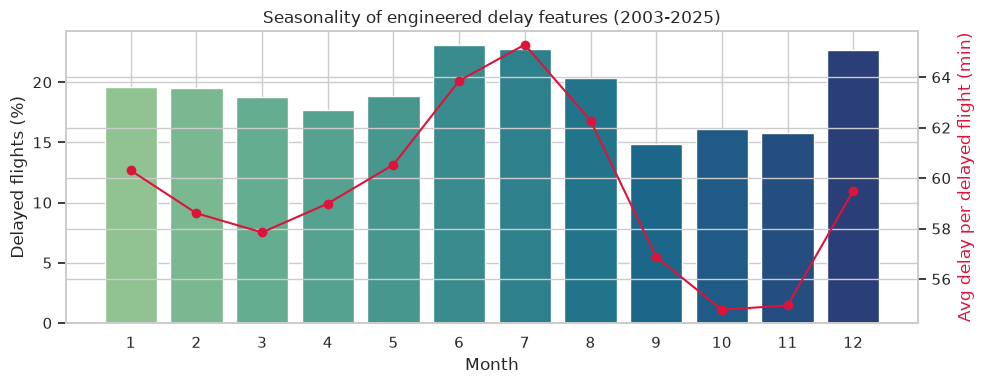

In [6]:
by_month = (
    clean.group_by("month")
    .agg(
        delay_rate=pl.col("arr_del15").sum() / pl.col("arr_flights").sum() * 100,
        avg_delay=pl.col("arr_delay").sum() / pl.col("arr_del15").sum(),
    )
    .sort("month")
)
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(by_month["month"], by_month["delay_rate"], color=sns.color_palette("crest", 12))
ax1.set_xlabel("Month")
ax1.set_ylabel("Delayed flights (%)")
ax1.set_xticks(range(1, 13))
ax2 = ax1.twinx()
ax2.plot(by_month["month"], by_month["avg_delay"], color="crimson", marker="o")
ax2.set_ylabel("Avg delay per delayed flight (min)", color="crimson")
plt.title("Seasonality of engineered delay features (2003-2025)")
plt.tight_layout()
save(fig, "features_seasonality")
plt.show()

#### 5.1 Verifying the derived columns
Every engineered column is recomputed independently in DuckDB SQL (a different engine than the Polars code that produced it) and compared row by row. Each count below must be `0`.

In [7]:
con = duckdb.connect()
feature_violations = con.execute(
    """
    SELECT
        COUNT(*) FILTER (WHERE period_start <> make_date(year::INT, month::INT, 1)) AS period_start,
        COUNT(*) FILTER (WHERE quarter <> (month - 1) // 3 + 1) AS quarter,
        COUNT(*) FILTER (WHERE season <> CASE WHEN month IN (12, 1, 2) THEN 'winter' WHEN month IN (3, 4, 5) THEN 'spring'
                                             WHEN month IN (6, 7, 8) THEN 'summer' ELSE 'autumn' END) AS season,
        COUNT(*) FILTER (WHERE is_peak_travel_month <> (month IN (6, 7, 8, 12))) AS is_peak_travel_month,
        COUNT(*) FILTER (WHERE is_covid_period <> (make_date(year::INT, month::INT, 1) BETWEEN DATE '2020-03-01' AND DATE '2021-12-01')) AS is_covid_period,
        COUNT(*) FILTER (WHERE operated_flights <> arr_flights - arr_cancelled - arr_diverted) AS operated_flights,
        COUNT(*) FILTER (WHERE abs(delay_rate - arr_del15 / arr_flights) > 1e-12) AS delay_rate,
        COUNT(*) FILTER (WHERE abs(cancellation_rate - arr_cancelled / arr_flights) > 1e-12) AS cancellation_rate,
        COUNT(*) FILTER (WHERE abs(avg_delay_minutes_per_delayed_flight
                                   - CASE WHEN arr_del15 > 0 THEN arr_delay / arr_del15 ELSE 0 END) > 1e-9) AS avg_delay_per_delayed,
        COUNT(*) FILTER (WHERE abs(avg_delay_minutes_per_operated_flight - arr_delay / operated_flights) > 1e-9) AS avg_delay_per_operated,
        COUNT(*) FILTER (WHERE arr_delay > 0 AND abs(carrier_delay_share + weather_delay_share + nas_delay_share
                                                   + security_delay_share + late_aircraft_delay_share - 1) * arr_delay > 1) AS shares_sum_to_1,
        COUNT(*) FILTER (WHERE dominant_delay_cause <> CASE
            WHEN arr_delay = 0 THEN 'none'
            WHEN carrier_delay = greatest(carrier_delay, weather_delay, nas_delay, security_delay, late_aircraft_delay) THEN 'carrier'
            WHEN weather_delay = greatest(weather_delay, nas_delay, security_delay, late_aircraft_delay) THEN 'weather'
            WHEN nas_delay = greatest(nas_delay, security_delay, late_aircraft_delay) THEN 'nas'
            WHEN security_delay >= late_aircraft_delay THEN 'security'
            ELSE 'late_aircraft' END) AS dominant_delay_cause,
        COUNT(*) FILTER (WHERE arr_del15 > 0 AND avg_delay_minutes_per_delayed_flight NOT BETWEEN 15 AND 1440) AS avg_delay_outside_15min_24h
    FROM clean
    """
).pl()
feature_violations = feature_violations.unpivot(variable_name="check", value_name="violations")
assert feature_violations["violations"].sum() == 0
RESULT_TABLES["feature_verification"] = write_csv(feature_violations, BENCHMARK_DIR / "feature_verification.csv")
display(feature_violations)

print("Worked example - Delta (DL) at Atlanta (ATL), July 2019:")
display(
    clean.filter((pl.col("carrier") == "DL") & (pl.col("airport") == "ATL") & (pl.col("year") == 2019) & (pl.col("month") == 7))
    .select(
        "arr_flights", "arr_del15", "arr_cancelled", "arr_diverted", "arr_delay",
        "operated_flights", "delay_rate", "avg_delay_minutes_per_delayed_flight", "dominant_delay_cause", "season", "quarter",
    )
)

check,violations
str,i64
"""period_start""",0
"""quarter""",0
"""season""",0
"""is_peak_travel_month""",0
"""is_covid_period""",0
"""operated_flights""",0
"""delay_rate""",0
"""cancellation_rate""",0
"""avg_delay_per_delayed""",0


Worked example - Delta (DL) at Atlanta (ATL), July 2019:


arr_flights,arr_del15,arr_cancelled,arr_diverted,arr_delay,operated_flights,delay_rate,avg_delay_minutes_per_delayed_flight,dominant_delay_cause,season,quarter
i64,i64,i64,i64,i64,i64,f64,f64,str,str,i8
21839,3506,78,74,298239,21687,0.160538,85.065317,"""late_aircraft""","""summer""",3


### 6. Physical partitioning (Hive layout, Snappy)
The clean dataset is written twice:
* `data/processed/bts_clean.parquet` - a single Snappy Parquet file (variant A of the benchmark).
* `data/partitioned/bts_by_carrier/` - a Hive-partitioned dataset via `pyarrow.parquet.write_to_dataset(partition_cols=['carrier'], compression='snappy')` (variant B).

**Why `carrier`?** The main consumers of the data are airline-level reports (on-time KPIs for one airline, airline vs. airline benchmarking, DOT complaints per carrier), so most queries carry `WHERE carrier = ...`. With 38 values the key has low cardinality: few directories, partitions big enough to avoid the small-files problem. It is also a natural access-control boundary, since one airline's analysts can be given read access to their `carrier=XX/` prefix only. The alternatives are compared below:

In [9]:
single_file_path = PROCESSED_DATA_DIR / "bts_clean.parquet"
clean.write_parquet(single_file_path, compression="snappy")

partitioned_root = write_partitioned_parquet(
    clean, PARTITIONED_DATA_DIR / "bts_by_carrier", partition_cols=["carrier"], compression="snappy"
)
print(f"Partitioned dataset written to: {partitioned_root}")

Partitioned dataset written to: /home/dewaszmi/studia/big-data-exercise-2026/data/partitioned/bts_by_carrier


In [8]:
single_file_kb = PROCESSED_DATA_DIR.joinpath("bts_clean.parquet").stat().st_size / 1024
key_candidates = {"carrier": ["carrier"], "year": ["year"], "airport": ["airport"], "carrier + year": ["carrier", "year"]}
key_rows = []
for name, cols in key_candidates.items():
    sizes = clean.group_by(cols).len()["len"]
    key_rows.append(
        {
            "partition_key": name,
            "partitions": sizes.len(),
            "min_rows": sizes.min(),
            "median_rows": int(sizes.median()),
            "max_rows": sizes.max(),
            "est_avg_file_kb": round(single_file_kb / sizes.len(), 1),
        }
    )
partition_key_candidates = pl.DataFrame(key_rows)
RESULT_TABLES["partition_key_candidates"] = write_csv(
    partition_key_candidates, BENCHMARK_DIR / "partition_key_candidates.csv"
)
partition_key_candidates

partition_key,partitions,min_rows,median_rows,max_rows,est_avg_file_kb
str,i64,i64,i64,i64,f64
"""carrier""",38,15,6931,45974,906.3
"""year""",23,1916,17554,25822,1497.4
"""airport""",420,1,384,3687,82.0
"""carrier + year""",439,3,887,2958,78.5


#### 6.1 Verify the directory structure on disk

In [10]:
subdirs = sorted(p.name for p in partitioned_root.iterdir() if p.is_dir())
print(f"{partitioned_root.relative_to(ROOT_DIR)}/  ({len(subdirs)} partitions)")
for name in subdirs[:5]:
    for f in sorted((partitioned_root / name).iterdir()):
        print(f"├── {name}/{f.name}")
print("├── ...")
for name in subdirs[-3:]:
    for f in sorted((partitioned_root / name).iterdir()):
        print(f"├── {name}/{f.name}")

assert all(name.startswith("carrier=") for name in subdirs)
assert len(subdirs) == clean["carrier"].n_unique()

data/partitioned/bts_by_carrier/  (38 partitions)
├── carrier=9E/edeb151bb27b452080026d0a40e62c79-0.parquet
├── carrier=9K/edeb151bb27b452080026d0a40e62c79-0.parquet
├── carrier=AA/edeb151bb27b452080026d0a40e62c79-0.parquet
├── carrier=AQ/edeb151bb27b452080026d0a40e62c79-0.parquet
├── carrier=AS/edeb151bb27b452080026d0a40e62c79-0.parquet
├── ...
├── carrier=YV/edeb151bb27b452080026d0a40e62c79-0.parquet
├── carrier=YX/edeb151bb27b452080026d0a40e62c79-0.parquet
├── carrier=ZW/edeb151bb27b452080026d0a40e62c79-0.parquet


In [11]:
partitions = describe_partitions(partitioned_root)
RESULT_TABLES["partitions"] = write_csv(partitions, BENCHMARK_DIR / "partitions.csv")
display(partitions.sort("rows", descending=True))

roundtrip = pl.scan_parquet(partitioned_root, hive_partitioning=True)
roundtrip_rows = roundtrip.select(pl.len()).collect().item()
assert roundtrip_rows == clean.height == partitions["rows"].sum()
assert set(partitions["compression"].unique()) == {"SNAPPY"}
assert "carrier" not in pq.read_schema(next(partitioned_root.glob("carrier=DL/*.parquet"))).names
print(f"Round-trip OK: {roundtrip_rows:,} rows, carrier column restored from directory names")

partition,files,rows,size_kb,compression
str,i64,i64,f64,str
"""carrier=OO""",1,45974,3734.3,"""SNAPPY"""
"""carrier=DL""",1,32041,2925.1,"""SNAPPY"""
"""carrier=MQ""",1,29646,2582.3,"""SNAPPY"""
"""carrier=EV""",1,26709,2298.3,"""SNAPPY"""
"""carrier=AA""",1,23680,2596.1,"""SNAPPY"""
"""carrier=UA""",1,22717,2091.3,"""SNAPPY"""
"""carrier=WN""",1,20985,2602.5,"""SNAPPY"""
"""carrier=YV""",1,17109,1263.4,"""SNAPPY"""
"""carrier=9E""",1,15735,1187.6,"""SNAPPY"""


Round-trip OK: 397,111 rows, carrier column restored from directory names


### 7. A/B benchmark: flat file (A) vs. partitioned directory (B)
**Variants**
* **A - flat file:** `bts_clean.parquet`, one Snappy Parquet file. Its row groups mix all carriers (the `carrier` min/max statistics of each of its 3 row groups cover `9E` to `YV`/`ZW`, i.e. practically every carrier), so the engine must read every row group: a full scan.
* **B - partitioned:** `bts_by_carrier/carrier=XX/`. A filter on `carrier` is resolved from the directory names, so only the matching folder is read (partition pruning).

**Methodology**
* Two query engines: **DuckDB** (SQL) and **Polars** (lazy API), same logical query on both layouts.
* Seven scenarios: the task's query (monthly averages for one carrier, `DL`) plus a large carrier (`OO`, 11.6% of rows), a small one (`HA`, 1.1%), two other query shapes, a 3-carrier `IN` filter, and a **control query without a carrier filter** where pruning cannot help.
* **Warm** runs (files in the OS page cache) and **cold** runs (pages evicted with `posix_fadvise(DONTNEED)` before every run, so data really comes from the SSD). DuckDB's own file cache is disabled.
* 20 repetitions per configuration after warm-up; within each repetition A and B run in random order to avoid drift bias. Before timing, results from A and B are asserted equal.
* Reported: mean, standard deviation, median, p95; **time gain = (A - B) / A** on the mean.

In [12]:
layouts = {LAYOUT_FLAT: single_file_path, LAYOUT_PARTITIONED: partitioned_root}
SPEC_SCENARIO = "monthly_kpis[DL]"
scenarios = [
    monthly_kpis("DL"),
    monthly_kpis("OO"),
    monthly_kpis("HA"),
    yearly_volume("DL"),
    top_airports("WN"),
    multi_carrier_kpis(["AA", "DL", "UA"]),
    all_carriers_kpis(),
]
print("Task query (DuckDB), {source} = read_parquet(<flat file>) or read_parquet(<dir>/**/*.parquet, hive_partitioning = true):")
print(scenarios[0].sql)
pl.DataFrame({"scenario": [s.name for s in scenarios], "description": [s.description for s in scenarios]})

Task query (DuckDB), {source} = read_parquet(<flat file>) or read_parquet(<dir>/**/*.parquet, hive_partitioning = true):

            SELECT month,
                   AVG(avg_delay_minutes_per_delayed_flight) AS avg_delay_min,
                   AVG(delay_rate) AS avg_delay_rate
            FROM {source}
            WHERE carrier = 'DL'
            GROUP BY month ORDER BY month
        


scenario,description
str,str
"""monthly_kpis[DL]""","""Avg delay & delay rate by mont…"
"""monthly_kpis[OO]""","""Avg delay & delay rate by mont…"
"""monthly_kpis[HA]""","""Avg delay & delay rate by mont…"
"""yearly_volume[DL]""","""Flights, delayed flights and d…"
"""top_airports[WN]""","""Top 10 airports by delay minut…"
"""monthly_kpis[AA+DL+UA]""","""Avg delay & delay rate by mont…"
"""monthly_kpis[ALL]""","""Control: avg delay & delay rat…"


#### 7.1 I/O per query (what the engine has to read)
Computed from the Parquet footers: compressed bytes of the column chunks needed by the query, after pruning files (partition directories) and row groups (min/max statistics). The cost column uses the AWS Athena / BigQuery on-demand model of **$5 per TB scanned**.

scenario,layout,files_read,files_total,row_groups_read,row_groups_total,scanned_mb,io_reduction_pct,usd_per_1k_queries
str,str,i64,i64,i64,i64,f64,f64,f64
"""monthly_kpis[DL]""","""A: flat file (full scan)""",1,1,3,3,3.969,0.0,0.01893
"""monthly_kpis[DL]""","""B: partitioned (pruning)""",1,38,2,2,0.321,91.9,0.00153
"""monthly_kpis[OO]""","""A: flat file (full scan)""",1,1,3,3,3.969,0.0,0.01893
"""monthly_kpis[OO]""","""B: partitioned (pruning)""",1,38,2,2,0.393,90.1,0.00188
"""monthly_kpis[HA]""","""A: flat file (full scan)""",1,1,3,3,3.969,0.0,0.01893
"""monthly_kpis[HA]""","""B: partitioned (pruning)""",1,38,1,1,0.039,99.0,0.00019
"""yearly_volume[DL]""","""A: flat file (full scan)""",1,1,3,3,2.156,0.0,0.01028
"""yearly_volume[DL]""","""B: partitioned (pruning)""",1,38,2,2,0.205,90.5,0.00098
"""top_airports[WN]""","""A: flat file (full scan)""",1,1,3,3,2.251,0.0,0.01073


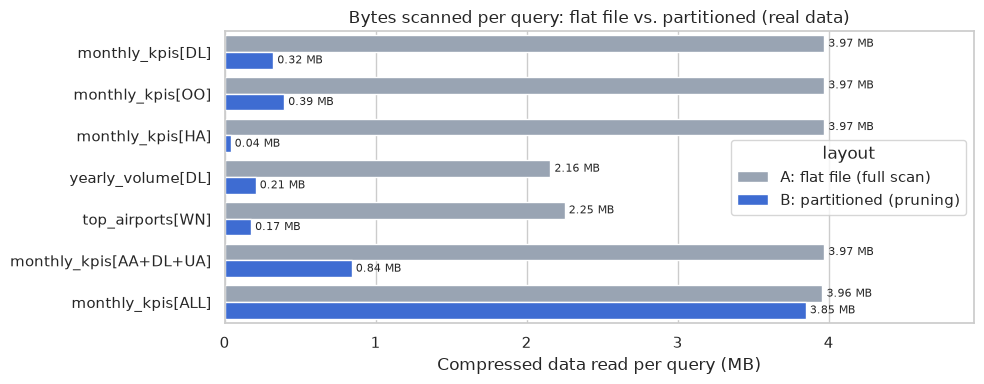

In [13]:
io = io_report(layouts, scenarios)
RESULT_TABLES["io_report"] = write_csv(io, BENCHMARK_DIR / "io_report.csv")
display(io.select("scenario", "layout", "files_read", "files_total", "row_groups_read", "row_groups_total",
                  pl.col("scanned_mb").round(3), pl.col("io_reduction_pct").round(1), pl.col("usd_per_1k_queries").round(5)))

fig, ax = plt.subplots(figsize=(10, 4))
io_plot = io.to_pandas()
sns.barplot(data=io_plot, y="scenario", x="scanned_mb", hue="layout", palette=LAYOUT_COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f MB", padding=3, fontsize=8)
ax.set_xlabel("Compressed data read per query (MB)")
ax.set_ylabel("")
ax.set_title("Bytes scanned per query: flat file vs. partitioned (real data)")
ax.set_xlim(0, io["scanned_mb"].max() * 1.25)
plt.tight_layout()
save(fig, "io_scanned_mb")
plt.show()

#### 7.2 Timing on the real dataset (397k rows, ~34 MB)

In [14]:
REPEATS = 20
start = time.perf_counter()
runs = run_ab_benchmark(layouts, scenarios, repeats=REPEATS)
print(f"{runs.height:,} timed runs in {time.perf_counter() - start:.0f} s")
RESULT_TABLES["runs_real"] = write_csv(runs, BENCHMARK_DIR / "runs_real.csv")

summary = summarize(runs)
RESULT_TABLES["summary_real"] = write_csv(summary, BENCHMARK_DIR / "summary_real.csv")
summary.with_columns(pl.col(pl.Float64).round(2))

1,120 timed runs in 29 s


scenario,engine,cache,A_n,A_mean_ms,A_std_ms,…,B_mean_ms,B_std_ms,B_median_ms,gain_pct,gain_pct_median,speedup
str,str,str,u32,f64,f64,…,f64,f64,f64,f64,f64,f64
"""monthly_kpis[AA+DL+UA]""","""duckdb""","""cold""",20,27.33,1.47,…,16.52,0.86,16.46,39.55,40.19,1.65
"""monthly_kpis[AA+DL+UA]""","""duckdb""","""warm""",20,18.53,2.27,…,12.98,1.23,12.65,29.96,33.81,1.43
"""monthly_kpis[AA+DL+UA]""","""polars""","""cold""",20,18.11,1.3,…,119.2,14.16,115.15,-558.21,-549.04,0.15
"""monthly_kpis[AA+DL+UA]""","""polars""","""warm""",20,12.01,0.98,…,83.83,5.51,83.34,-597.97,-597.88,0.14
"""monthly_kpis[ALL]""","""duckdb""","""cold""",20,22.14,1.88,…,30.65,3.55,29.91,-38.45,-34.7,0.72
"""monthly_kpis[ALL]""","""duckdb""","""warm""",20,11.34,0.83,…,16.56,1.62,16.03,-45.98,-43.32,0.69
"""monthly_kpis[ALL]""","""polars""","""cold""",20,20.07,1.87,…,50.42,1.38,50.16,-151.3,-148.04,0.4
"""monthly_kpis[ALL]""","""polars""","""warm""",20,14.18,2.3,…,15.55,1.21,15.24,-9.64,-7.14,0.91
"""monthly_kpis[DL]""","""duckdb""","""cold""",20,20.73,1.18,…,16.14,1.52,15.82,22.15,24.84,1.28


#### 7.3 Comparison table for the task query (`carrier = 'DL'`, monthly averages)

In [15]:
def fmt_table(df: pl.DataFrame) -> pl.DataFrame:
    return df.select(
        *[c for c in ("scale", "scenario", "engine", "cache") if c in df.columns],
        A_flat_ms=pl.format("{} ± {}", pl.col("A_mean_ms").round(1), pl.col("A_std_ms").round(1)),
        B_partitioned_ms=pl.format("{} ± {}", pl.col("B_mean_ms").round(1), pl.col("B_std_ms").round(1)),
        gain_pct=pl.col("gain_pct").round(1),
        gain_pct_median=pl.col("gain_pct_median").round(1),
        speedup=pl.col("speedup").round(2),
    )


fmt_table(summary.filter(pl.col("scenario") == SPEC_SCENARIO))

scenario,engine,cache,A_flat_ms,B_partitioned_ms,gain_pct,gain_pct_median,speedup
str,str,str,str,str,f64,f64,f64
"""monthly_kpis[DL]""","""duckdb""","""cold""","""20.7 ± 1.2""","""16.1 ± 1.5""",22.2,24.8,1.28
"""monthly_kpis[DL]""","""duckdb""","""warm""","""10.6 ± 1.4""","""10.4 ± 0.7""",1.8,-0.0,1.02
"""monthly_kpis[DL]""","""polars""","""cold""","""14.5 ± 1.1""","""40.3 ± 1.6""",-177.6,-180.4,0.36
"""monthly_kpis[DL]""","""polars""","""warm""","""8.5 ± 0.5""","""10.0 ± 0.9""",-17.8,-18.1,0.85


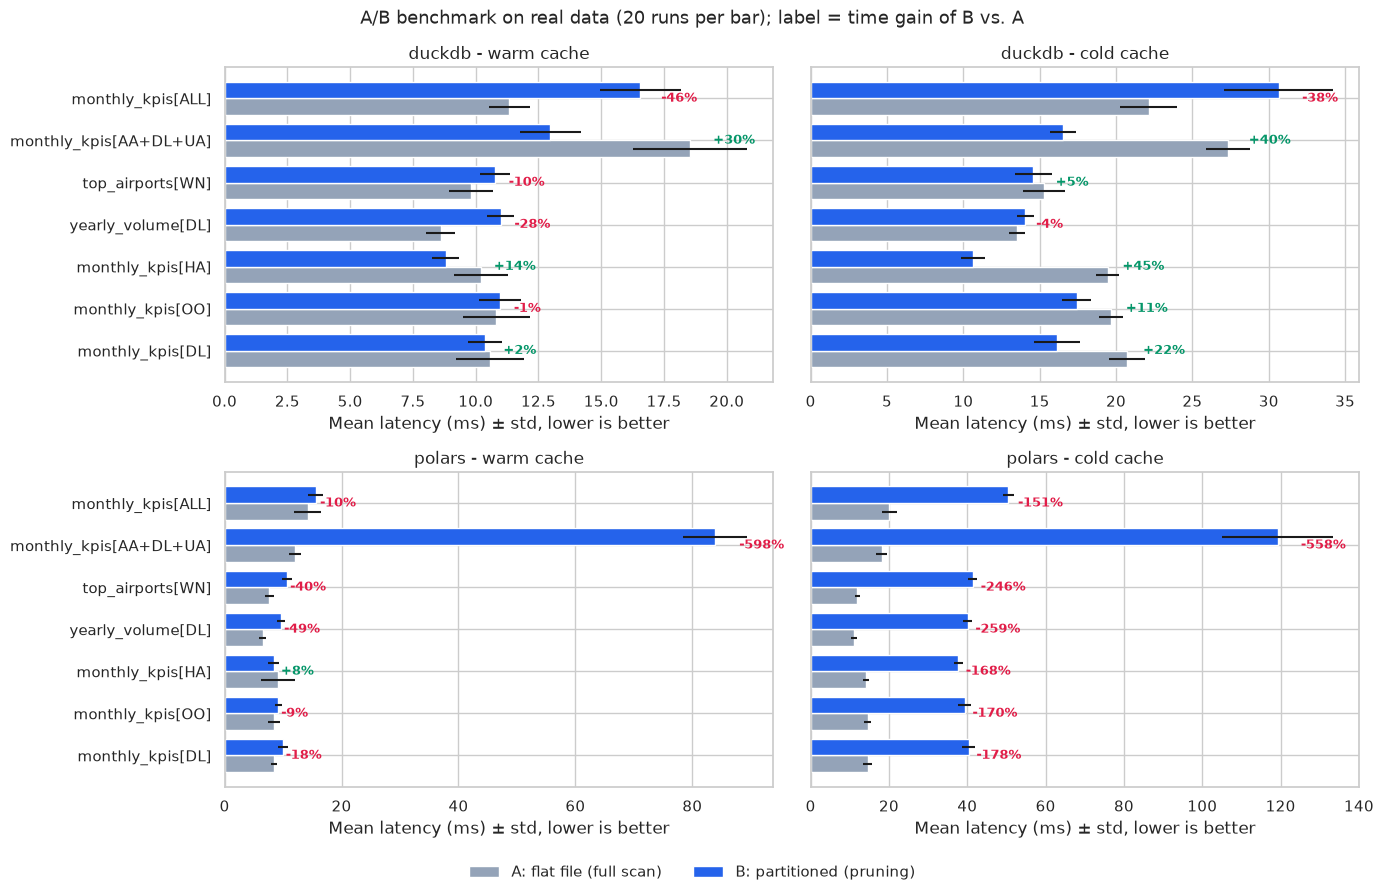

In [16]:
scenario_order = [s.name for s in scenarios]
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for (i, engine), (j, cache) in [((i, e), (j, c)) for i, e in enumerate(["duckdb", "polars"]) for j, c in enumerate(["warm", "cold"])]:
    ax = axes[i][j]
    sub = summary.filter((pl.col("engine") == engine) & (pl.col("cache") == cache))
    sub = sub.sort(pl.col("scenario").replace_strict({s: k for k, s in enumerate(scenario_order)}))
    y = range(sub.height)
    ax.barh([k - 0.2 for k in y], sub["A_mean_ms"], xerr=sub["A_std_ms"], height=0.4, color=LAYOUT_COLORS[LAYOUT_FLAT], label=LAYOUT_FLAT)
    ax.barh([k + 0.2 for k in y], sub["B_mean_ms"], xerr=sub["B_std_ms"], height=0.4, color=LAYOUT_COLORS[LAYOUT_PARTITIONED], label=LAYOUT_PARTITIONED)
    for k, (b, g) in enumerate(zip(sub["B_mean_ms"], sub["gain_pct"])):
        ax.text(max(b, sub["A_mean_ms"][k]) * 1.05, k, f"{g:+.0f}%", va="center", fontsize=9,
                color="#059669" if g > 0 else "#e11d48", fontweight="bold")
    ax.set_yticks(list(y), sub["scenario"])
    ax.invert_yaxis()
    ax.set_title(f"{engine} - {cache} cache")
    ax.set_xlabel("Mean latency (ms) ± std, lower is better")
fig.suptitle(f"A/B benchmark on real data ({REPEATS} runs per bar); label = time gain of B vs. A", fontsize=13)
fig.legend(*axes[0][0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "ab_real_latency")
plt.show()

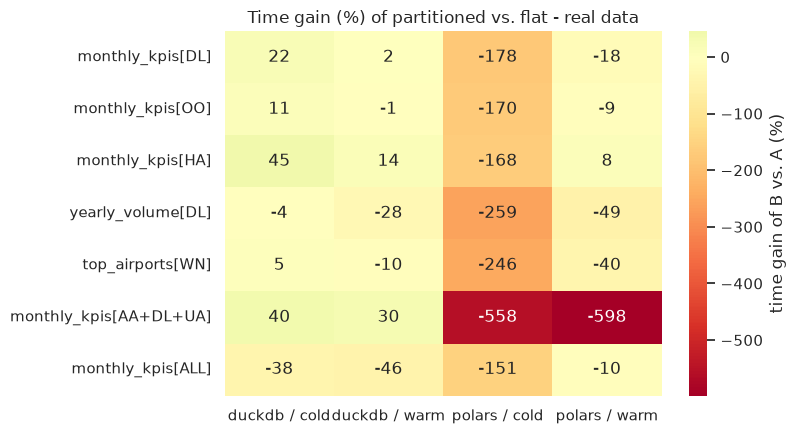

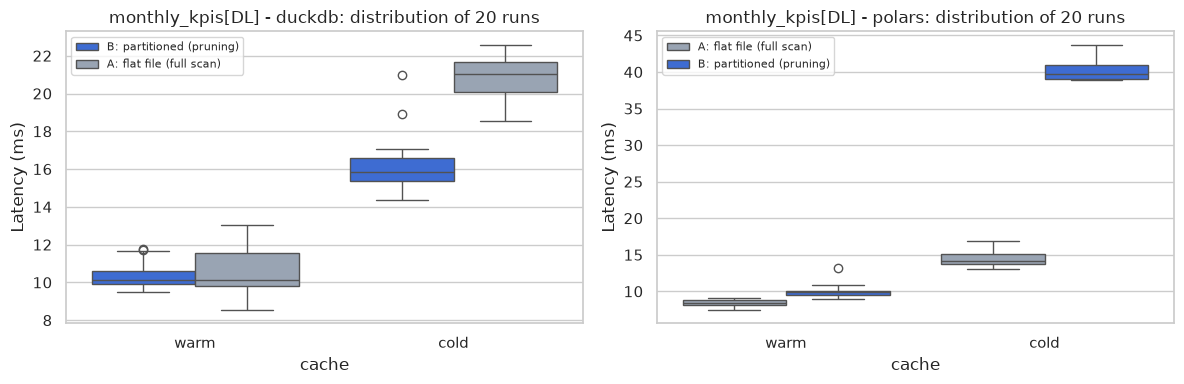

In [17]:
gain = (
    summary.with_columns(config=pl.format("{} / {}", "engine", "cache"))
    .pivot(on="config", index="scenario", values="gain_pct")
    .sort(pl.col("scenario").replace_strict({s: k for k, s in enumerate(scenario_order)}))
)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(gain.to_pandas().set_index("scenario"), annot=True, fmt=".0f", center=0, cmap="RdYlGn", cbar_kws={"label": "time gain of B vs. A (%)"}, ax=ax)
ax.set_title("Time gain (%) of partitioned vs. flat - real data")
ax.set_ylabel("")
ax.set_xlabel("")
plt.tight_layout()
save(fig, "ab_real_gain_heatmap")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
spec_runs = runs.filter(pl.col("scenario") == SPEC_SCENARIO).to_pandas()
for ax, engine in zip(axes, ["duckdb", "polars"]):
    sns.boxplot(data=spec_runs[spec_runs["engine"] == engine], x="cache", y="ms", hue="layout", palette=LAYOUT_COLORS, ax=ax)
    ax.set_title(f"{SPEC_SCENARIO} - {engine}: distribution of {REPEATS} runs")
    ax.set_ylabel("Latency (ms)")
    ax.legend(fontsize=8)
plt.tight_layout()
save(fig, "ab_real_boxplot")
plt.show()

#### 7.4 Why partitioning barely helps at 34 MB - and where the time goes
On the real dataset a query reads only ~4 MB of compressed column data even with a full scan, which takes a few milliseconds from the page cache. At that size latency is dominated by fixed per-file costs (listing directories, opening files, parsing footers), and the partitioned layout has 38 files instead of 1.

The two engines handle the Hive layout differently:
* **DuckDB** applies the `carrier` filter to the directory names before opening any file (`Scanning Files: 1/38` in the plan).
* **Polars** reads the footer of every file under the root during planning to resolve the schema, and only then prunes. With a cold cache that alone costs tens of ms, so cold Polars runs on B pay for 38 footer reads. On object storage (S3/GCS) every footer read is a separate billed GET request with ~10-50 ms latency.
* **Polars, grouping by the partition column** (`monthly_kpis[AA+DL+UA]` groups by `carrier, month`): the optimizer rewrites the aggregation into a `UNION` of one sub-plan per partition file (38 plans, 35 of them empty), which costs ~70-80 ms regardless of pruning. Visible with `.explain()`; DuckDB does not do this.


In [18]:
plan = con.execute(
    f"EXPLAIN SELECT COUNT(*) FROM read_parquet('{partitioned_root}/**/*.parquet', hive_partitioning = true) WHERE carrier = 'DL'"
).fetchall()[0][1]
print("DuckDB partition pruning:", next(line.strip(" │") for line in plan.splitlines() if "Files" in line))


def cold_ms(fn, path, repeats=5):
    if not COLD_CACHE_SUPPORTED:
        return None
    timings = []
    for _ in range(repeats):
        evict_page_cache(path)
        start = time.perf_counter()
        fn()
        timings.append((time.perf_counter() - start) * 1000)
    return round(statistics.median(timings), 1)


dl_dir = partitioned_root / "carrier=DL"
pl.DataFrame(
    {
        "polars operation (cold cache)": [
            "resolve schema of the Hive root (reads all 38 footers)",
            "monthly_kpis[DL] via Hive root",
            "monthly_kpis[DL] reading carrier=DL/ directly",
        ],
        "median_ms": [
            cold_ms(lambda: pl.scan_parquet(partitioned_root, hive_partitioning=True).collect_schema(), partitioned_root),
            cold_ms(lambda: scenarios[0].polars(pl.scan_parquet(partitioned_root, hive_partitioning=True)).collect(), partitioned_root),
            cold_ms(lambda: scenarios[0].polars(pl.scan_parquet(dl_dir).with_columns(carrier=pl.lit("DL"))).collect(), partitioned_root),
        ],
    }
)

DuckDB partition pruning: Scanning Files: 1/38


polars operation (cold cache),median_ms
str,f64
"""resolve schema of the Hive roo…",32.4
"""monthly_kpis[DL] via Hive root""",40.7
"""monthly_kpis[DL] reading carri…",8.3


### 8. Scale-up experiment: when does partition pruning pay off?
The clean dataset is replicated 1x, 5x, 20x and 50x (up to ~20M rows; the flight-level BTS on-time table has ~7M rows per year) with DuckDB `COPY ... TO` in streaming mode, and written in all three layouts with identical settings (Snappy, 122,880-row row groups, `PARTITION_BY (carrier)` for B; A' is B's rows written to one file). The same protocol is repeated (10 runs per configuration) for the task query on `DL`, the small carrier `HA` and the no-filter control.

Copies are appended as whole blocks, and copy *k* shifts every measure by *k* (integers) or *k*·10⁻⁶ (floats): copy 0 is the real data, later copies keep its value distribution but share no values with it. Byte-identical copies would be a trap: B and A' place ~4 copies of a carrier's rows in one row group, dictionary encoding stores each repeated value once, and both layouts would look ~30% smaller and faster than on genuinely new data (section 11). Each scale's files are deleted after measuring (three layouts at 50x take ~5 GB).

In [19]:
SCALES = [1, 5, 20, 50]
scale_scenarios = [monthly_kpis("DL"), monthly_kpis("HA"), all_carriers_kpis()]
start = time.perf_counter()
scale = run_scale_experiment(single_file_path, BENCHMARK_DIR, SCALES, scale_scenarios, repeats=10)
print(f"Scale experiment finished in {time.perf_counter() - start:.0f} s")
RESULT_TABLES["runs_scale"] = write_csv(scale["runs"], BENCHMARK_DIR / "runs_scale.csv")
scale_summary = summarize(scale["runs"], by=("scale", "scenario", "engine", "cache"))
RESULT_TABLES["summary_scale"] = write_csv(scale_summary, BENCHMARK_DIR / "summary_scale.csv")
RESULT_TABLES["io_report_scale"] = write_csv(scale["io"], BENCHMARK_DIR / "io_report_scale.csv")

storage = scale["storage"].pivot(on="layout", index=["scale", "rows"], values="size_mb")
storage_view = storage.with_columns(
    pl.col(LAYOUT_FLAT).round(1), pl.col(LAYOUT_SORTED).round(1), pl.col(LAYOUT_PARTITIONED).round(1),
    sorted_vs_flat_pct=((pl.col(LAYOUT_SORTED) / pl.col(LAYOUT_FLAT) - 1) * 100).round(1),
    partitioned_vs_flat_pct=((pl.col(LAYOUT_PARTITIONED) / pl.col(LAYOUT_FLAT) - 1) * 100).round(1),
)
RESULT_TABLES["storage_by_scale"] = write_csv(storage_view, BENCHMARK_DIR / "storage_by_scale.csv")
storage_view

Scale experiment finished in 172 s


scale,rows,A: flat file (full scan),B: partitioned (pruning),partitioned_vs_flat_pct
i64,i64,f64,f64,f64
1,397111,31.0,34.0,9.9
5,1985555,153.7,116.8,-24.0
20,7942220,614.6,436.2,-29.0
50,19855550,1536.5,1073.6,-30.1


In [20]:
fmt_table(scale_summary.filter(pl.col("scenario") == SPEC_SCENARIO))

scale,scenario,engine,cache,A_flat_ms,B_partitioned_ms,gain_pct,gain_pct_median,speedup
i64,str,str,str,str,str,f64,f64,f64
1,"""monthly_kpis[DL]""","""duckdb""","""cold""","""16.5 ± 0.8""","""13.0 ± 1.3""",21.1,23.3,1.27
1,"""monthly_kpis[DL]""","""duckdb""","""warm""","""10.0 ± 1.0""","""9.8 ± 1.2""",2.3,11.0,1.02
1,"""monthly_kpis[DL]""","""polars""","""cold""","""13.5 ± 0.8""","""32.1 ± 1.7""",-138.5,-141.2,0.42
1,"""monthly_kpis[DL]""","""polars""","""warm""","""8.1 ± 0.7""","""9.6 ± 0.7""",-19.2,-17.9,0.84
5,"""monthly_kpis[DL]""","""duckdb""","""cold""","""44.4 ± 3.3""","""19.8 ± 1.3""",55.5,54.2,2.25
5,"""monthly_kpis[DL]""","""duckdb""","""warm""","""18.6 ± 0.6""","""12.4 ± 1.5""",33.4,36.9,1.5
5,"""monthly_kpis[DL]""","""polars""","""cold""","""28.7 ± 0.8""","""41.4 ± 1.2""",-44.5,-44.2,0.69
5,"""monthly_kpis[DL]""","""polars""","""warm""","""19.7 ± 1.2""","""11.8 ± 0.7""",40.4,39.0,1.68
20,"""monthly_kpis[DL]""","""duckdb""","""cold""","""139.3 ± 7.5""","""26.5 ± 1.9""",81.0,80.8,5.26


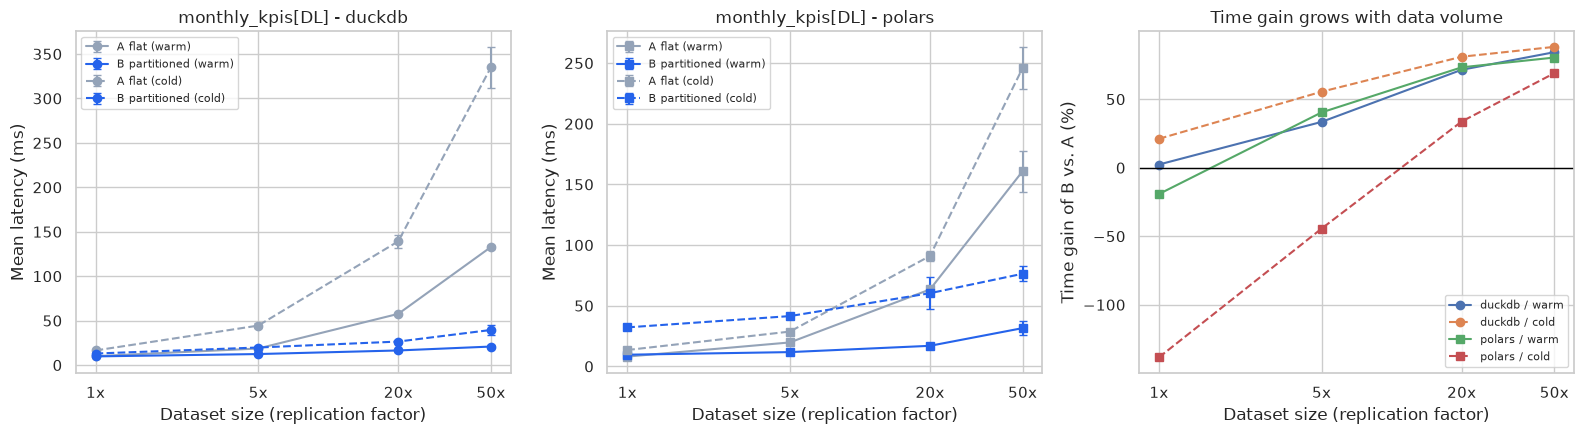

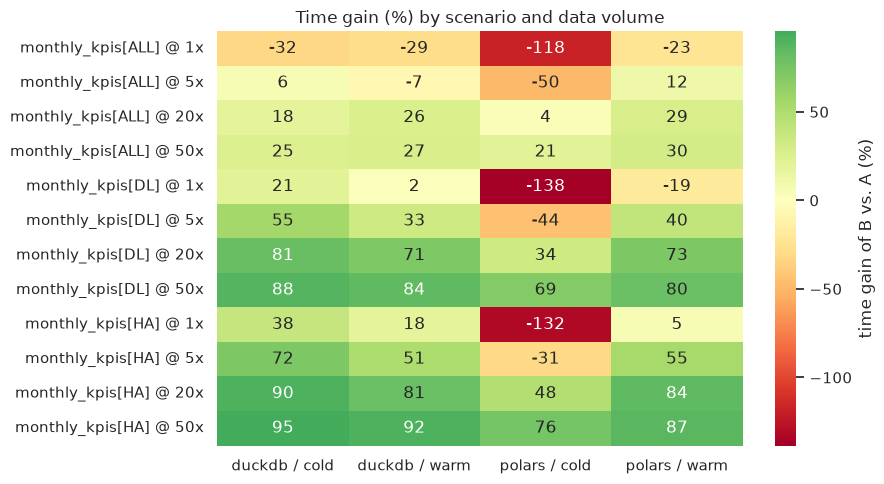

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
spec_scale = scale_summary.filter(pl.col("scenario") == SPEC_SCENARIO)
styles = {("duckdb", "warm"): ("-", "o"), ("duckdb", "cold"): ("--", "o"), ("polars", "warm"): ("-", "s"), ("polars", "cold"): ("--", "s")}
for engine, ax in zip(["duckdb", "polars"], axes[:2]):
    for cache in ["warm", "cold"]:
        sub = spec_scale.filter((pl.col("engine") == engine) & (pl.col("cache") == cache)).sort("scale")
        ls, marker = styles[(engine, cache)]
        ax.errorbar(sub["scale"], sub["A_mean_ms"], yerr=sub["A_std_ms"], ls=ls, marker=marker, color=LAYOUT_COLORS[LAYOUT_FLAT], label=f"A flat ({cache})", capsize=3)
        ax.errorbar(sub["scale"], sub["B_mean_ms"], yerr=sub["B_std_ms"], ls=ls, marker=marker, color=LAYOUT_COLORS[LAYOUT_PARTITIONED], label=f"B partitioned ({cache})", capsize=3)
    ax.set_xscale("log")
    ax.set_xticks(SCALES, [f"{s}x" for s in SCALES])
    ax.set_xlabel("Dataset size (replication factor)")
    ax.set_ylabel("Mean latency (ms)")
    ax.set_title(f"{SPEC_SCENARIO} - {engine}")
    ax.legend(fontsize=8)

ax = axes[2]
for (engine, cache), (ls, marker) in styles.items():
    sub = spec_scale.filter((pl.col("engine") == engine) & (pl.col("cache") == cache)).sort("scale")
    ax.plot(sub["scale"], sub["gain_pct"], ls=ls, marker=marker, label=f"{engine} / {cache}")
ax.axhline(0, color="black", lw=1)
ax.set_xscale("log")
ax.set_xticks(SCALES, [f"{s}x" for s in SCALES])
ax.set_xlabel("Dataset size (replication factor)")
ax.set_ylabel("Time gain of B vs. A (%)")
ax.set_title("Time gain grows with data volume")
ax.legend(fontsize=8)
plt.tight_layout()
save(fig, "scale_latency_gain")
plt.show()

scale_gain = (
    scale_summary.with_columns(config=pl.format("{} / {}", "engine", "cache"))
    .pivot(on="config", index=["scenario", "scale"], values="gain_pct")
    .sort("scenario", "scale")
)
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    scale_gain.to_pandas().assign(row=lambda d: d["scenario"] + " @ " + d["scale"].astype(str) + "x").set_index("row").drop(columns=["scenario", "scale"]),
    annot=True, fmt=".0f", center=0, cmap="RdYlGn", cbar_kws={"label": "time gain of B vs. A (%)"}, ax=ax,
)
ax.set_title("Time gain (%) by scenario and data volume")
ax.set_ylabel("")
plt.tight_layout()
save(fig, "scale_gain_heatmap")
plt.show()

### 9. FinOps: what partitioning saves per query
In cloud warehouses (AWS Athena, BigQuery on-demand, Redshift Spectrum) the bill is proportional to **bytes scanned**, not to wall-clock time. The scanned volume per query is therefore the cost metric. It is independent of caching and of the local SSD.

In [22]:
QUERIES_PER_MONTH = 100_000
io_scale = (
    scale["io"].filter(pl.col("scenario") == SPEC_SCENARIO)
    .pivot(on="layout", index="scale", values="scanned_mb")
    .rename({LAYOUT_FLAT: "A_scanned_mb", LAYOUT_SORTED: "A_sorted_scanned_mb", LAYOUT_PARTITIONED: "B_scanned_mb"})
    .with_columns(
        io_reduction_pct=(1 - pl.col("B_scanned_mb") / pl.col("A_scanned_mb")) * 100,
        A_usd_month=pl.col("A_scanned_mb") / 1024**2 * 5 * QUERIES_PER_MONTH,
        B_usd_month=pl.col("B_scanned_mb") / 1024**2 * 5 * QUERIES_PER_MONTH,
    )
    .sort("scale")
)
print(f"{SPEC_SCENARIO}: scanned data and Athena cost for {QUERIES_PER_MONTH:,} queries / month at $5 per TB")
finops_scale = io_scale.with_columns(pl.col(pl.Float64).round(2))
RESULT_TABLES["finops_scale"] = write_csv(finops_scale, BENCHMARK_DIR / "finops_scale.csv")
finops_scale

monthly_kpis[DL]: scanned data and Athena cost for 100,000 queries / month at $5 per TB


scale,A_scanned_mb,B_scanned_mb,io_reduction_pct,A_usd_month,B_usd_month
i32,f64,f64,f64,f64,f64
1,3.79,0.33,91.22,1.81,0.16
5,19.12,1.16,93.91,9.12,0.56
20,76.49,4.48,94.14,36.47,2.14
50,191.23,10.9,94.3,91.18,5.2


### 10. Context: raw CSV vs. Parquet
For reference, the same task query on the raw CSV (text parsing, all columns, no statistics) against both Parquet layouts, DuckDB, warm cache.

In [23]:
csv_source = f"read_csv('{BTS_CSV_PATH}')"
csv_sql = scenarios[0].sql.replace("AVG(avg_delay_minutes_per_delayed_flight)", "AVG(CASE WHEN arr_del15 > 0 THEN arr_delay / arr_del15 ELSE 0 END)").replace(
    "AVG(delay_rate)", "AVG(arr_del15 / arr_flights)"
)
csv_con = duckdb.connect()
csv_con.execute("SET enable_external_file_cache = false")


def timed(sql, repeats=10):
    csv_con.execute(sql).fetchall()
    timings = []
    for _ in range(repeats):
        start = time.perf_counter()
        csv_con.execute(sql).fetchall()
        timings.append((time.perf_counter() - start) * 1000)
    return statistics.mean(timings)


format_rows = [
    {"format": "raw CSV", "size_mb": BTS_CSV_PATH.stat().st_size / 1024**2,
     "mean_ms": timed(csv_sql.format(source=csv_source))},
    {"format": "A: flat Parquet", "size_mb": size_mb(single_file_path),
     "mean_ms": timed(scenarios[0].sql.format(source=f"read_parquet('{single_file_path}')"))},
    {"format": "B: partitioned Parquet", "size_mb": size_mb(partitioned_root),
     "mean_ms": timed(scenarios[0].sql.format(source=f"read_parquet('{partitioned_root}/**/*.parquet', hive_partitioning = true)"))},
]
csv_vs_parquet = pl.DataFrame(format_rows).with_columns(
    pl.col("size_mb").round(1),
    pl.col("mean_ms").round(1),
    speedup_vs_csv=(pl.col("mean_ms").first() / pl.col("mean_ms")).round(1),
)
RESULT_TABLES["csv_vs_parquet"] = write_csv(csv_vs_parquet, BENCHMARK_DIR / "csv_vs_parquet.csv")
csv_vs_parquet

format,size_mb,mean_ms,speedup_vs_csv
str,f64,f64,f64
"""raw CSV""",50.7,264.7,1.0
"""A: flat Parquet""",33.6,11.8,22.4
"""B: partitioned Parquet""",35.2,10.4,25.6


### 11. Check: partitioning or just sorting? (disk metrics only)
Two questions the timings above cannot answer on their own:
1. **Is B's I/O gain about directories, or about rows being grouped by carrier?** A' (`bts_clean_sorted.parquet`, 16,384-row row groups) holds B's rows in B's order in a single file, so the difference between A' and B is the directory layout alone.
2. **Were the earlier scale-up results inflated by identical copies?** The first version of section 8 appended byte-identical copies. Below, the same layouts are built with identical and with distinct copies.

Everything here is computed from file sizes and Parquet footers (compressed bytes of the column chunks a query must read after pruning files and row groups), so it does not depend on the machine, OS or cache.

layout,size_mb,files,row_groups,rows
str,f64,i64,i64,i64
"""A: flat file (full scan)""",33.7,1,5,397111
"""A': flat file sorted by carrier (row-group pruning)""",34.5,1,25,397111
"""B: partitioned (pruning)""",35.2,38,50,397111


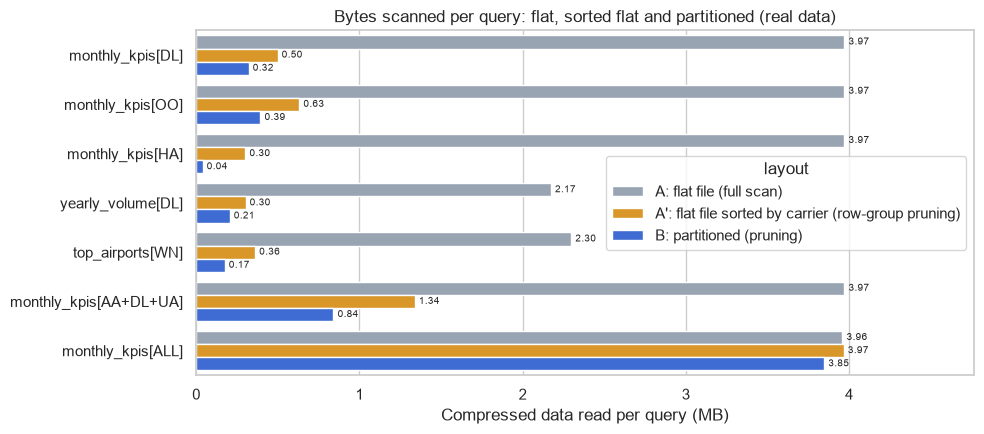

scenario,A_mb,A_sorted_mb,B_mb,A_sorted_reduction_pct,B_reduction_pct
str,f64,f64,f64,f64,f64
"""monthly_kpis[DL]""",3.971,0.499,0.321,87.4,91.9
"""monthly_kpis[OO]""",3.971,0.632,0.393,84.1,90.1
"""monthly_kpis[HA]""",3.971,0.301,0.039,92.4,99.0
"""yearly_volume[DL]""",2.173,0.302,0.205,86.1,90.6
"""top_airports[WN]""",2.298,0.361,0.174,84.3,92.4
"""monthly_kpis[AA+DL+UA]""",3.971,1.339,0.841,66.3,78.8
"""monthly_kpis[ALL]""",3.959,3.967,3.847,-0.2,2.8


In [2]:
single_file_path = PROCESSED_DATA_DIR / "bts_clean.parquet"
sorted_file_path = PROCESSED_DATA_DIR / "bts_clean_sorted.parquet"
partitioned_root = PARTITIONED_DATA_DIR / "bts_by_carrier"
if not sorted_file_path.exists():
    write_sorted_parquet(pl.read_parquet(single_file_path), sorted_file_path)
three_layouts = {LAYOUT_FLAT: single_file_path, LAYOUT_SORTED: sorted_file_path, LAYOUT_PARTITIONED: partitioned_root}
SHORT = {LAYOUT_FLAT: "A", LAYOUT_SORTED: "A'", LAYOUT_PARTITIONED: "B"}
check_scenarios = [
    monthly_kpis("DL"), monthly_kpis("OO"), monthly_kpis("HA"), yearly_volume("DL"),
    top_airports("WN"), multi_carrier_kpis(["AA", "DL", "UA"]), all_carriers_kpis(),
]

layout_storage = pl.DataFrame([{"layout": name, **storage_info(path)} for name, path in three_layouts.items()])
RESULT_TABLES["layout_storage_real"] = write_csv(layout_storage, BENCHMARK_DIR / "layout_storage_real.csv")
display(layout_storage.with_columns(pl.col("size_mb").round(1)))

io3 = io_report(three_layouts, check_scenarios)
scanned = io3.with_columns(pl.col("layout").replace_strict(SHORT)).pivot(on="layout", index="scenario", values="scanned_mb")
io_sorted_vs_partitioned = scanned.select(
    "scenario",
    A_mb=pl.col("A").round(3),
    A_sorted_mb=pl.col("A'").round(3),
    B_mb=pl.col("B").round(3),
    A_sorted_reduction_pct=((1 - pl.col("A'") / pl.col("A")) * 100).round(1),
    B_reduction_pct=((1 - pl.col("B") / pl.col("A")) * 100).round(1),
)
RESULT_TABLES["io_sorted_vs_partitioned"] = write_csv(io_sorted_vs_partitioned, BENCHMARK_DIR / "io_sorted_vs_partitioned.csv")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=io3.to_pandas(), y="scenario", x="scanned_mb", hue="layout", palette=LAYOUT_COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=7)
ax.set_xlabel("Compressed data read per query (MB)")
ax.set_ylabel("")
ax.set_title("Bytes scanned per query: flat, sorted flat and partitioned (real data)")
ax.set_xlim(0, io3["scanned_mb"].max() * 1.2)
plt.tight_layout()
save(fig, "io_sorted_vs_partitioned")
plt.show()
io_sorted_vs_partitioned

In [3]:
REPL_SCALES = [1, 5, 20, 50]
repl_scenarios = [monthly_kpis("DL"), monthly_kpis("HA"), all_carriers_kpis()]
start = time.perf_counter()
replication = {
    "identical copies (old)": run_storage_experiment(single_file_path, BENCHMARK_DIR, [5, 20, 50], repl_scenarios, distinct_copies=False),
    "distinct copies (fixed)": run_storage_experiment(single_file_path, BENCHMARK_DIR, REPL_SCALES, repl_scenarios),
}
print(f"Built and measured {sum(r['storage'].height for r in replication.values())} layouts in {time.perf_counter() - start:.0f} s")

replication_storage = (
    pl.concat([r["storage"].with_columns(copies=pl.lit(name)) for name, r in replication.items()])
    .with_columns(pl.col("layout").replace_strict(SHORT))
    .pivot(on="layout", index=["copies", "scale", "rows"], values="size_mb")
    .select(
        "copies", "scale", "rows",
        A_mb=pl.col("A").round(1), A_sorted_mb=pl.col("A'").round(1), B_mb=pl.col("B").round(1),
        A_sorted_vs_A_pct=((pl.col("A'") / pl.col("A") - 1) * 100).round(1),
        B_vs_A_pct=((pl.col("B") / pl.col("A") - 1) * 100).round(1),
        A_bytes_per_row=(pl.col("A") * 1024**2 / pl.col("rows")).round(1),
    )
)
RESULT_TABLES["replication_storage"] = write_csv(replication_storage, BENCHMARK_DIR / "replication_storage.csv")
replication_storage

Built and measured 21 layouts in 75 s


copies,scale,rows,A_mb,A_sorted_mb,B_mb,A_sorted_vs_A_pct,B_vs_A_pct,A_bytes_per_row
str,i64,i64,f64,f64,f64,f64,f64,f64
"""identical copies (old)""",5,1985555,153.0,120.8,116.9,-21.1,-23.5,80.8
"""identical copies (old)""",20,7942220,611.5,384.8,434.7,-37.1,-28.9,80.7
"""identical copies (old)""",50,19855550,1529.0,908.8,1064.5,-40.6,-30.4,80.7
"""distinct copies (fixed)""",1,397111,30.8,30.3,33.9,-1.7,9.9,81.4
"""distinct copies (fixed)""",5,1985555,158.4,171.6,175.6,8.4,10.9,83.6
"""distinct copies (fixed)""",20,7942220,636.7,707.2,713.5,11.1,12.1,84.1
"""distinct copies (fixed)""",50,19855550,1593.9,1766.7,1784.7,10.8,12.0,84.2


In [4]:
QUERIES_PER_MONTH = 100_000
replication_io = (
    pl.concat([r["io"].with_columns(copies=pl.lit(name)) for name, r in replication.items()])
    .with_columns(pl.col("layout").replace_strict(SHORT))
    .pivot(on="layout", index=["copies", "scale", "scenario"], values="scanned_mb")
    .select(
        "copies", "scale", "scenario",
        A_mb=pl.col("A").round(2), A_sorted_mb=pl.col("A'").round(2), B_mb=pl.col("B").round(2),
        A_sorted_reduction_pct=((1 - pl.col("A'") / pl.col("A")) * 100).round(1),
        B_reduction_pct=((1 - pl.col("B") / pl.col("A")) * 100).round(1),
        A_usd_month=(pl.col("A") / 1024**2 * 5 * QUERIES_PER_MONTH).round(2),
        A_sorted_usd_month=(pl.col("A'") / 1024**2 * 5 * QUERIES_PER_MONTH).round(2),
        B_usd_month=(pl.col("B") / 1024**2 * 5 * QUERIES_PER_MONTH).round(2),
    )
    .sort("copies", "scenario", "scale")
)
RESULT_TABLES["replication_io"] = write_csv(replication_io, BENCHMARK_DIR / "replication_io.csv")
replication_io

copies,scale,scenario,A_mb,A_sorted_mb,B_mb,A_sorted_reduction_pct,B_reduction_pct,A_usd_month,A_sorted_usd_month,B_usd_month
str,i32,str,f64,f64,f64,f64,f64,f64,f64,f64
"""distinct copies (fixed)""",1,"""monthly_kpis[ALL]""",3.73,3.71,3.94,0.6,-5.7,1.78,1.77,1.88
"""distinct copies (fixed)""",5,"""monthly_kpis[ALL]""",19.6,21.44,21.3,-9.4,-8.6,9.35,10.22,10.16
"""distinct copies (fixed)""",20,"""monthly_kpis[ALL]""",79.57,87.31,87.01,-9.7,-9.3,37.94,41.63,41.49
"""distinct copies (fixed)""",50,"""monthly_kpis[ALL]""",199.5,218.34,218.01,-9.4,-9.3,95.13,104.11,103.96
"""distinct copies (fixed)""",1,"""monthly_kpis[DL]""",3.74,1.22,0.33,67.4,91.2,1.78,0.58,0.16
"""distinct copies (fixed)""",5,"""monthly_kpis[DL]""",19.67,2.75,1.76,86.0,91.0,9.38,1.31,0.84
"""distinct copies (fixed)""",20,"""monthly_kpis[DL]""",79.84,8.41,7.2,89.5,91.0,38.07,4.01,3.43
"""distinct copies (fixed)""",50,"""monthly_kpis[DL]""",200.17,19.49,18.0,90.3,91.0,95.45,9.29,8.58
"""distinct copies (fixed)""",1,"""monthly_kpis[HA]""",3.74,0.96,0.04,74.3,98.9,1.78,0.46,0.02


**What this changes**
* **Sorting alone gets most of B's I/O gain.** On the real data A' reads 0.50 MB for the task query, B 0.32 MB, A 3.97 MB (-87% vs. -92%). At 20M rows (50x, 122,880-row row groups) the gap is 90.3% vs. 91.0%. The directories add little on top of sorting; their remaining advantages are operational: skipped partitions cost no footer read at all, access can be granted per `carrier=XX/` prefix, and a partition is dropped by deleting a folder.
* **Identical copies inflated B in the first version of section 8.** With byte-identical copies B at 50x was 30% *smaller* than A, which was used to explain why even the no-filter control query got faster. A' shrank even more (-41%), so the effect came from duplicate rows sitting next to each other, not from partitioning. With distinct copies B is 12% *larger* than A (at 1x, with no copies at all: +10%), the control query reads 9% more on B, and the task query's I/O reduction stays at 91% at every scale instead of creeping up to 94%.
* Distinct copies stay realistic: A needs 84 bytes per row at 50x vs. 81 on the real data.

### 12. Export raw results for the presentation
Same workflow as Milestone 1 (`data/profiling_results.txt`): every table the slides need is written as CSV under `data/benchmark/`, then concatenated into a single narrative-free text dump. The HTML presentation is generated from that file plus this notebook (and the charts in `presentation/figures/`).

In [ ]:
task_query_summary = fmt_table(summary.filter(pl.col("scenario") == SPEC_SCENARIO))
RESULT_TABLES["task_query_comparison_monthly_kpis_DL"] = write_csv(
    task_query_summary, BENCHMARK_DIR / "task_query_comparison_monthly_kpis_DL.csv"
)
RESULT_TABLES["summary_scale_task_query"] = write_csv(
    fmt_table(scale_summary.filter(pl.col("scenario") == SPEC_SCENARIO)),
    BENCHMARK_DIR / "summary_scale_task_query.csv",
)

written = save_milestone2_results(
    RESULT_TABLES,
    txt_path=CLEANING_BENCHMARK_TXT_PATH,
    also_copy_to=PRESENTATION_RESULTS_TXT_PATH,
)
print("Presentation input artifacts:")
for label, path in written.items():
    print(f"  {label}: {path.relative_to(ROOT_DIR)}")
print(f"  CSVs: {len(RESULT_TABLES)} files in {BENCHMARK_DIR.relative_to(ROOT_DIR)}/")
print(f"  Figures: {len(list(FIGURES_DIR.glob('*.png')))} PNGs in {FIGURES_DIR.relative_to(ROOT_DIR)}/")

### Conclusions
**Cleaning and features**
* 398,233 raw rows -> 397,111 clean rows (-1,122, 0.28%). Business rules drop 962 rows (950 with missing measurements, 2 with negative delay components, 12 with broken sum invariants; a row can break several rules), telemetry rules drop 160 more (mostly months in which every flight was cancelled or diverted, plus 5 averages above 24 h per delayed flight).
* 18 engineered features, every one re-derived independently in DuckDB SQL with 0 mismatches over 397k rows.

**Storage layout**
* 38 `carrier=XX/` directories, one Snappy Parquet file each, `carrier` lives only in the path. Sorting by the partition key before writing matters: unsorted input produced 276 row groups instead of 50 and a 22% larger dataset.
* `carrier` is the right granularity here; `airport` or `carrier + year` would produce 420-439 files of ~80 KB each (small-files problem).
* Partitioning costs disk: the partitioned dataset is 4-12% larger than the flat file (38 files, each with its own dictionaries and footer). The earlier "30% smaller at 50x" was an artifact of byte-identical copies (section 11).

**A/B benchmark**
* **I/O / FinOps:** for queries filtered by carrier, partition pruning cuts the bytes read by 79-99% (task query on `DL`: -92%, about 12x less data), at every scale. The control query without a carrier filter gains nothing, as expected. On pay-per-scan engines (Athena, BigQuery) this translates 1:1 into the bill.
* **Most of that comes from sorting, not from directories:** a single file sorted by carrier (A') reads 66-92% less than A on the real data, and 90% vs. 91% less than A for the task query at 20M rows.
* **Latency on the real 34 MB dataset** is mixed: the whole file is read in ~10 ms, so fixed per-file costs (38 files, footers) dominate. DuckDB still wins for most carrier queries on a cold cache (up to ~45%); Polars loses, because it reads all 38 footers before pruning and splits group-bys on the partition column into per-file plans.
* **Latency at scale:** with 5x-50x the data, the flat file grows linearly while the partitioned query only reads one carrier. At 50x the task query was 84-88% faster on B for DuckDB and 69-80% for Polars.
* **Takeaway:** partitioning is a bet on the query pattern and on data volume. It pays off when most queries filter on the key and partitions are large (tens of MB and up); on a 34 MB dataset its main benefit is fewer bytes scanned, not speed, and a file sorted by the same key gets most of that benefit too.